# Mamba in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/ccr-9d70e555-krj2ct/examples/notebooks/mamba.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/ccr-9d70e555-krj2ct/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

A port of [mamba-jax](https://github.com/vvvm23/mamba-jax) (Equinox) to expex:
[`examples/mamba/mamba.py`](../mamba/mamba.py). Every module states its sizes
(`Mixer[D, E, N, R, K]`: width `D`, inner width `E`, state `N`, dt rank `R`, conv width `K`),
the selective scan is a plain `for` loop over time (staged as a `lax.scan`), and per-token
layers are written for one token.

This notebook runs it on a small model, shows what expex reads from the annotations, checks it
against the original's saved outputs, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "ccr-9d70e555-krj2ct"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples" / "mamba"))
print("examples from", REPO)

examples from .


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import mamba  # examples/mamba/mamba.py
from mamba import Mamba

print(inspect.getsource(mamba.selective_scan))
print(inspect.getsource(mamba.Mixer.__call__))

@fn
def selective_scan[T, E, N](
    u: f32[T, E], dt: f32[T, E], A: f32[E, N], B: f32[T, N], C: f32[T, N]
) -> f32[T, E]:
    """h_t = exp(dt_t A) h_{t-1} + dt_t u_t B_t,  y_t = h_t C_t."""
    h = jnp.zeros((E, N))
    ys = []
    for t in range(T):  # a lax.scan carrying h
        h = jnp.exp(dt[t][:, None] * A) * h + (dt[t] * u[t])[:, None] * B[t]
        ys.append(h @ C[t])
    return jnp.asarray(ys)

    def __call__[T](self, x: f32[T, D]) -> f32[T, D]:
        xz = x @ self.in_proj.T
        u, z = xz[:, :E], xz[:, E:]
        u = jax.nn.silu(self.conv(u))
        dbc = u @ self.x_proj.T
        dt, B, C = dbc[:, :R], dbc[:, R : R + N], dbc[:, R + N :]
        dt = jax.nn.softplus(dt @ self.dt_weight.T + self.dt_bias)
        y = selective_scan(u, dt, -jnp.exp(self.A_log), B, C) + u * self.skip
        return (y * jax.nn.silu(z)) @ self.out_proj.T



## The annotated signatures

Every typed function and method in the module, as expex reads it:

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(mamba):
    print(signature(report.fn))

RMSNorm.__call__(self: RMSNorm, x: f32[D]) -> f32[D]
selective_scan[T, E, N](u: f32[T, E], dt: f32[T, E], A: f32[E, N], B: f32[T, N], C: f32[T, N]) -> f32[T, E]
Mixer.__call__[T](self: Mixer, x: f32[T, D]) -> f32[T, D]
Mixer.conv[T](self: Mixer, u: f32[T, E]) -> f32[T, E]
Mixer.step(self: Mixer, x: f32[D], state: State[E, N, K]) -> tuple[f32[D], State[E, N, K]]
Block.__call__[T](self: Block, h: f32[T, D]) -> f32[T, D]
Block.step(self: Block, h: f32[D], state: State[E, N, K]) -> tuple[f32[D], State[E, N, K]]
Mamba.create(cls, key: Key, vocab: int, d: int, layers: int, state: int, conv: int, expand: int)
Mamba.__call__[T](self: Mamba, tokens: Int[T]) -> f32[T, V]
Mamba.loss[T](self: Mamba, tokens: Int[T]) -> f32[()]
Mamba.step(self: Mamba, token: Int[()], states: list[State[E, N, K]]) -> tuple[f32[V], list[State[E, N, K]]]
Mamba.generate[T](self: Mamba, prompt: Int[T], n: int, key: Key, temperature: float) -> Int[T + n]


`expex.debug.shapes` shows the shape of every line of the mixer, for all sizes at once:

In [4]:
print(expex.debug.shapes(mamba.Mixer.__call__))

__call__[T](self: Mixer, x: f32[T, D]) -> f32[T, D]   [symbolic D, E, K, N, R, T]
   86 |     def __call__[T](self, x: f32[T, D]) -> f32[T, D]:
   87 |         xz = x @ self.in_proj.T                                            # xz: f32[T, 2*E]
   88 |         u, z = xz[:, :E], xz[:, E:]                                        # u: f32[T, E], z: f32[T, E]
   89 |         u = jax.nn.silu(self.conv(u))                                      # u: f32[T, E]
   90 |         dbc = u @ self.x_proj.T                                            # dbc: f32[T, R + 2*N]
   91 |         dt, B, C = dbc[:, :R], dbc[:, R : R + N], dbc[:, R + N :]          # dt: f32[T, R], B: f32[T, N], C: f32[T, N]
   92 |         dt = jax.nn.softplus(dt @ self.dt_weight.T + self.dt_bias)         # dt: f32[T, E]
   93 |         y = selective_scan(u, dt, -jnp.exp(self.A_log), B, C) + u * self.skip   # y: f32[T, E]
   94 |         return (y * jax.nn.silu(z)) @ self.out_proj.T                      # -> f32[T, D]


## Run it

A small model: vocabulary 100, width 64, 3 layers. `Mamba.create` derives the inner width, the
dt rank and the padded vocabulary from the original's settings. The model is written for one
sequence; a batch maps over its rows.

In [5]:
model = Mamba.create(jr.key(0), vocab=100, d=64, layers=3)
tokens = jr.randint(jr.key(1), (8, 32), 0, 100)  # 8 sequences of 32 tokens

print("logits", model(tokens[0]).shape, "for one sequence;", model(tokens).shape, "for the batch")
print("loss", float(model.loss(tokens).mean()))
print("sampled", model.generate(tokens[0, :8], 8, jr.key(2)))
print("how the loop in selective_scan ran:", mamba.selective_scan.flow)

logits (32, 100) for one sequence; (8, 32, 100) for the batch


loss 4.758768558502197


sampled [96 27 40 53 68 84 38 81 84 12 94 74  1 59 85 22]
how the loop in selective_scan ran: {43: 'for -> lax.scan (carries h)'}


## What the annotations give

**Proofs** for every size, without data:

In [6]:
expex.prove(mamba)

ok    mamba.RMSNorm.__call__
ok    mamba.selective_scan
ok    mamba.Mixer.__call__
ok    mamba.Mixer.conv
ok    mamba.Mixer.step
ok    mamba.Block.__call__
ok    mamba.Block.step
ok    mamba.Mamba.create
ok    mamba.Mamba.__call__
ok    mamba.Mamba.loss
ok    mamba.Mamba.step
ok    mamba.Mamba.generate

12 functions: 12 proved

**A summary** of the model, and its **cost** as formulas in the sizes:

In [7]:
expex.summary(model, T=32)

Mamba   (T=32, V=100, P=104, D=64, E=128, N=16, R=4, K=4, L=3)
module           class                                     params  formula                                                                  bytes   flops  flops formula
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
embedding        f32[P, D]                                  6,656  P·D                                                                    26.6 kB
layers[*]        Block[D=64, E=128, N=16, R=4, K=4]  × 3   32,768  3·D·E + 3·E·N + 2·E·R + E·K + 3·E + 2·D                                 131 kB  2.49 M  11·T·E·N + 6·T·D·E + 4·T·E·R + 2·T·E·K + 20·T·E + 6·T·D + 4·T·K + 2·E·N + 24·T + 2·K
  norm           RMSNorm[D=64]                                128  2·D                                                                      512 B     323  5·D + 3
    weight       f32[D]                           

In [8]:
print(expex.cost(Mamba.__call__))

Mamba.__call__   (sizes: T, V, P, D, E, N, R, K, L)
  flops        11·T·E·N·L + 6·T·D·E·L + 4·T·E·R·L + 2·T·E·K·L + 20·T·E·L + 6·T·D·L + 4·T·K·L + 2·T·V·D + 2·E·N·L + 24·T·L + 5·T·D + 2·K·L + 6·T
  parameters   3·D·E·L + 3·E·N·L + 2·E·R·L + E·K·L + 3·E·L + 2·D·L + V·D + P·D + 2·D
  largest      f32[T,K,E] (T·E·K elements)
  note: L = len(self.layers)


**A diagram** drawn from the code: the selective scan is a container `loop × T`. When you run
the notebook it is an interactive page: click a call to open it.

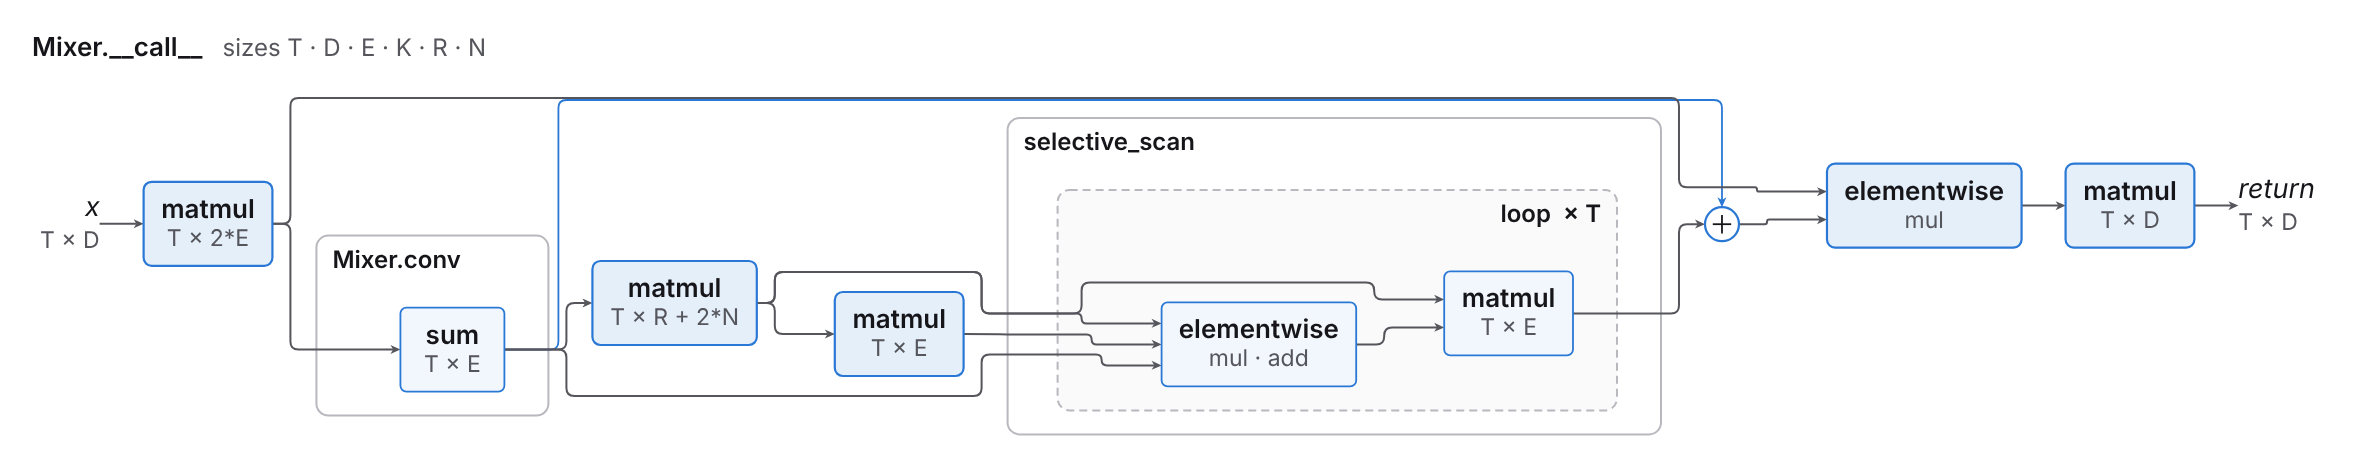

In [9]:
expex.diagram(mamba.Mixer.__call__, depth=2)

**`expex.inspect`**: every tool in one page, with activations and gradients of the loss.

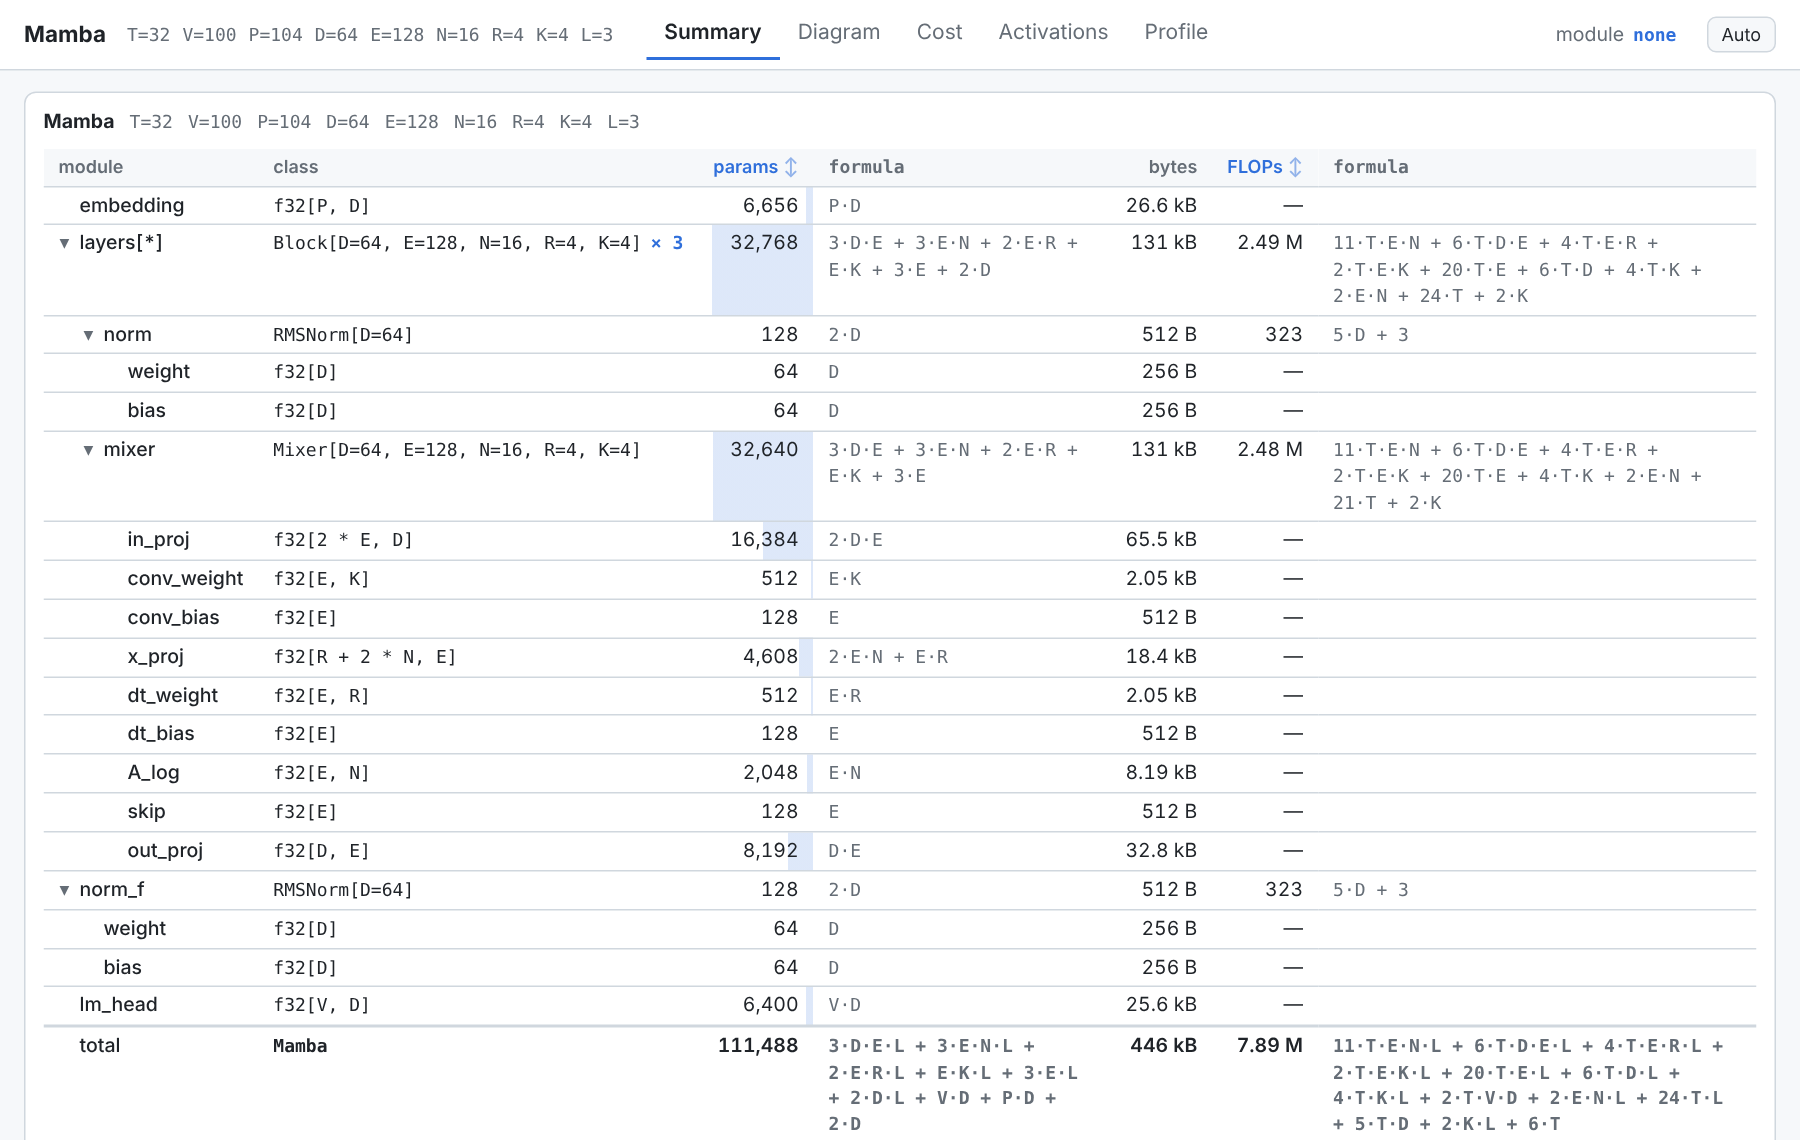

In [10]:
expex.inspect(model, tokens[0], loss=lambda m, t: m.loss(t))

## A shape error

Changing part of a model with `.at` is checked against its annotation. `x_proj` is
`f32[R + 2 * N, E]`; a replacement with one row too few says which size disagrees:

In [11]:
mixer = model.layers[0].mixer
try:
    model.at.layers[0].mixer.x_proj.set(jnp.zeros((mixer.x_proj.shape[0] - 1, mixer.x_proj.shape[1])))
except expex.ShapeError as e:
    error = e
error

ShapeError: Mamba.at.layers[0].mixer.x_proj.set(...): `layers[0].mixer.x_proj` is f32[35, 128], but is declared f32[R + 2 * N, E].

    axis 0 should be R + 2 * N = 36 (with N=16, R=4), but is 35.
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex308


## Activations and gradients, layer by layer

`expex.debug.watch` runs one forward and backward pass and reports every typed call:

In [12]:
watch = expex.debug.watch(lambda m: m.loss(tokens[0]), model)
print(f"{len(watch.rows)} calls, {len(watch.flagged)} flagged")
watch

18 calls, 0 flagged


watch <lambda>: loss 4.70668, 18 calls, 0 flagged  (grad_ratio=100.0, growth=10.0)
                                                    ─────────────────────output────────────────────  ───────────────d loss / d output────────────────
  call                            shape         ×n       mean       std    |max|       rms  nan/inf       mean       std     |max|       rms  nan/inf  flags
  Mamba.loss                      f32            1       4.71         0     4.71      4.71                   1         0         1         1
    Mamba.__call__                f32[31, 100]   1    0.00877     0.571     1.99     0.572            4.21e-12   0.00321    0.0322   0.00321
      layers[0].__call__          f32[31, 64]    1    -0.0069     0.998     3.39     0.998           -4.39e-05   0.00232   0.00504   0.00232
        layers[0].norm.__call__   f32[64]       31   -0.00682         1     3.15         1            1.14e-06  9.86e-05  0.000378  9.87e-05
        layers[0].mixer.__call__  f32[31, 64] 

## Against the original

`tests/data/mamba_reference.npz` holds the parameters of a small model built by the unmodified
mamba-jax, its logits (with its sequential and its associative scan), the gradients of a loss
and the tokens it samples. `compare.py` loads those parameters into the port and measures the
largest differences:

In [13]:
import compare  # examples/mamba/compare.py

reference = dict(np.load(REPO / "tests" / "data" / "mamba_reference.npz"))
for name, diff in compare.compare(reference).items():
    print(f"{name:28} {diff:.3g}")

logits                       5.96e-07
logits (associative scan)    5.96e-07
loss                         4.77e-07
gradients (relative)         8.35e-07
sampled tokens differing     0


## Speed

Compiled forward pass, gradients and sampling at the small size above. Timings depend on the
machine, so compare them only with each other. The repository's
[benchmarks/](../../benchmarks/) compare the port with the original: 10-14x faster forward and
5-6x faster gradients on CPU, generation the same.

In [14]:
def bench(f, *args, n=20):
    """Median seconds per call, after a first call that compiles."""
    jax.block_until_ready(f(*args))
    times = []
    for _ in range(n):
        start = time.perf_counter()
        jax.block_until_ready(f(*args))
        times.append(time.perf_counter() - start)
    return float(np.median(times))


forward = jax.jit(lambda m, t: m(t))
grads = jax.jit(jax.grad(lambda m, t: m.loss(t).mean()))
sample = jax.jit(lambda m, p, k: m.generate(p, 16, k))
print(f"forward, 8 x 32 tokens   {bench(forward, model, tokens) * 1e3:7.2f} ms")
print(f"gradients, 8 x 32 tokens {bench(grads, model, tokens) * 1e3:7.2f} ms")
print(f"sample 16 tokens         {bench(sample, model, tokens[0, :8], jr.key(3)) * 1e3:7.2f} ms")

forward, 8 x 32 tokens      4.15 ms


gradients, 8 x 32 tokens   26.82 ms


sample 16 tokens            0.67 ms
